In [ ]:
!pip install mcda==0.4.1

In [ ]:
from mcda.core.performance_table import *
from mcda.core.scales import *
from mcda.plot import *
from mcda.core.matrices import AdjacencyMatrix
from mcda.outranking.electre import *

In [ ]:
scales = {
    "World Ranking": QuantitativeScale(1, 500, PreferenceDirection.MIN),                      # Lower ranking is better
    "Scholarships (€)": QuantitativeScale(0, 15000, PreferenceDirection.MAX),
    "Cost of Living (€)": QuantitativeScale(600, 2000, PreferenceDirection.MIN),              # Lower is better
    "Life Expectancy (Years)": QuantitativeScale(76, 85, PreferenceDirection.MAX),
    "Salary After Graduation (€)": QuantitativeScale(20000, 120000, PreferenceDirection.MAX),
    "Distance from Barcelona (km)": QuantitativeScale(0, 12000, PreferenceDirection.MAX)      # Further is better
}

In [ ]:
alternatives = [
    "Albert-Ludwigs-Universität Freiburg",
    "University of Buenos Aires",
    "Université Catholique de Louvain",
    "Politecnico di Milano",
    "Georgia Institute of Technology",
    "Technische Universität München",
    "Pontificia Universidad Católica de Chile",
    "ETH Zurich",
    "Aalto University",
    "National Taiwan University of Science and Technology",
    "University of Edinburgh",
    "University of Oulu"
]

criteria = {
    "World Ranking": 0.25,
    "Scholarships (€)": 0.15,
    "Cost of Living (€)": 0.15,
    "Life Expectancy (Years)": 0.10,
    "Salary After Graduation (€)": 0.25,
    "Distance from Barcelona (km)": 0.10
}


In [ ]:
performance_table = PerformanceTable(
        [[192, 10000, 1200, 81, 55000, 1100],
        [71, 0, 600, 76, 18000, 10000],
        [170, 5000, 1000, 80, 42000, 1200],
        [123, 6000, 1200, 82, 32000, 1200],
        [88, 15000, 1500, 79, 85000, 8000],
        [37, 12000, 1300, 80, 60000, 1400],
        [121, 8000, 800, 81, 28000, 10000],
        [7, 10000, 1800, 84, 90000, 1000],
        [109, 5000, 1100, 82, 48000, 2000],
        [387, 4000, 700, 80, 30000, 11000],
        [22, 7000, 1300, 82, 50000, 1500],
        [313, 6000, 900, 81, 45000, 2100]],
        alternatives = alternatives,
        criteria = criteria,
        scales = scales)

performance_table.df

,World Ranking,Scholarships (€),Cost of Living (€),Life Expectancy (Years),Salary After Graduation (€),Distance from Barcelona (km)
Albert-Ludwigs-Universität Freiburg,192,10000,1200,81,55000,1100
University of Buenos Aires,71,0,600,76,18000,10000
Université Catholique de Louvain,170,5000,1000,80,42000,1200
Politecnico di Milano,123,6000,1200,82,32000,1200
Georgia Institute of Technology,88,15000,1500,79,85000,8000
Technische Universität München,37,12000,1300,80,60000,1400
Pontificia Universidad Católica de Chile,121,8000,800,81,28000,10000
ETH Zurich,7,10000,1800,84,90000,1000
Aalto University,109,5000,1100,82,48000,2000
National Taiwan University of Science and Technology,387,4000,700,80,30000,11000


In [ ]:
# Indifference thresholds
q = {
    "World Ranking": 5,
    "Scholarships (€)": 500,
    "Cost of Living (€)": 100,
    "Life Expectancy (Years)": 1,
    "Salary After Graduation (€)": 2000,
    "Distance from Barcelona (km)": 50
}

# Preference thresholds
p = {
    "World Ranking": 30,
    "Scholarships (€)": 1500,
    "Cost of Living (€)": 500,
    "Life Expectancy (Years)": 5,
    "Salary After Graduation (€)": 10000,
    "Distance from Barcelona (km)": 300
}

# Veto thresholds
v = {
    "World Ranking": 100,
    "Scholarships (€)": 7000,
    "Cost of Living (€)": 1000,
    "Life Expectancy (Years)": 10,
    "Salary After Graduation (€)": 25000,
    "Distance from Barcelona (km)": 700
}


,Albert-Ludwigs-Universität Freiburg,University of Buenos Aires,Université Catholique de Louvain,Politecnico di Milano,Georgia Institute of Technology,Technische Universität München,Pontificia Universidad Católica de Chile,ETH Zurich,Aalto University,National Taiwan University of Science and Technology,University of Edinburgh,University of Oulu
Albert-Ludwigs-Universität Freiburg,1.00000,0.5000,0.7725,0.7300,0.250,0.40625,0.5375,0.45000,0.65000,0.7500,0.65000,0.82500
University of Buenos Aires,0.50000,1.0000,0.5250,0.5000,0.550,0.27500,0.5000,0.25000,0.50000,0.4250,0.25000,0.50000
Université Catholique de Louvain,0.60000,0.5375,1.0000,0.6500,0.250,0.29000,0.4625,0.27500,0.50000,0.8250,0.28750,0.79375
Politecnico di Milano,0.60000,0.5000,0.7125,1.0000,0.250,0.29000,0.6375,0.32500,0.56000,0.7500,0.32500,0.57500
Georgia Institute of Technology,0.90000,0.6300,0.8500,0.8750,1.000,0.71250,0.7250,0.55625,0.83750,0.7500,0.66250,0.82500
Technische Universität München,1.00000,0.7500,0.9250,0.9750,0.500,1.00000,0.7500,0.42500,0.83750,0.7500,0.85500,0.78750
Pontificia Universidad Católica de Chile,0.60000,0.7125,0.7500,0.9375,0.350,0.35000,1.0000,0.30000,0.68000,0.9000,0.50000,0.75000
ETH Zurich,0.83000,0.7500,0.7900,0.7900,0.675,0.60000,0.7500,1.00000,0.75000,0.7500,0.75000,0.75000
Aalto University,0.69375,0.5000,1.0000,0.9250,0.340,0.35000,0.6750,0.32500,1.00000,0.7875,0.60000,0.86750
National Taiwan University of Science and Technology,0.35000,0.7500,0.4250,0.5750,0.350,0.35000,0.6000,0.27500,0.40000,1.0000,0.32500,0.35000


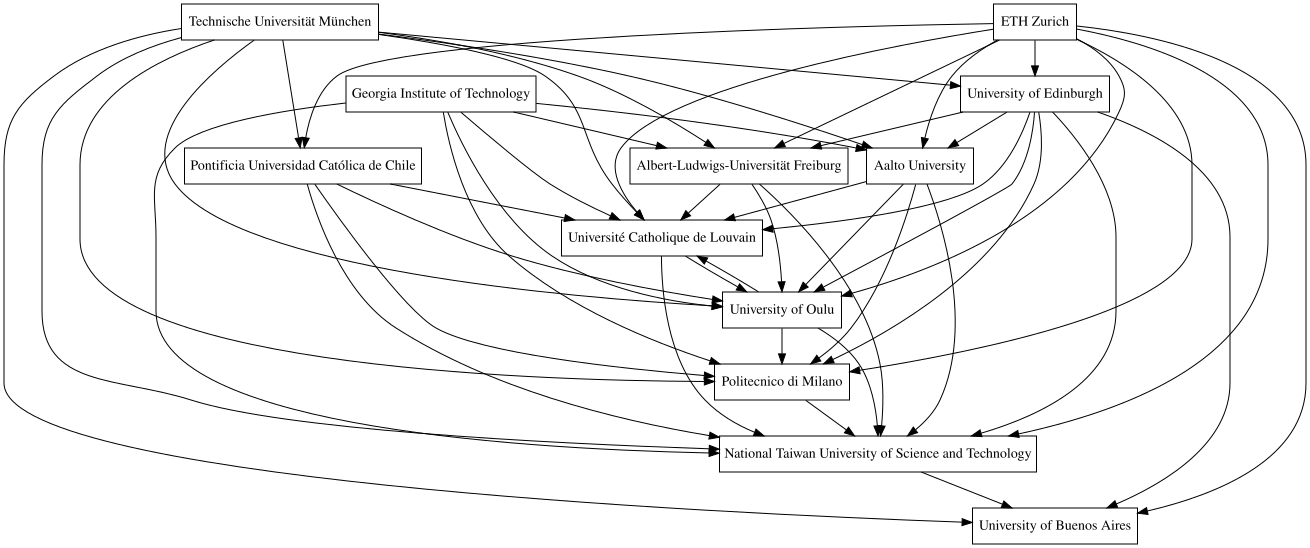

In [ ]:
electre3 = Electre3(criteria_weights=criteria, preference_thresholds=p, indifference_thresholds=q, veto_thresholds=v, alpha=0.2, beta=-0.1)
concordance_matrix = electre3.concordance(performance_table)

display(concordance_matrix)

#Now we plot the graph of concordance with relations above the cut threshold
cut_threshold = 0.75
conc_mat_cut = concordance_matrix.where(concordance_matrix >= cut_threshold, other=0)
AdjacencyMatrix(conc_mat_cut).plot()

In [ ]:
discordance_matrix = electre3.discordance(performance_table)
discordance_matrix


,Albert-Ludwigs-Universität Freiburg,University of Buenos Aires,Université Catholique de Louvain,Politecnico di Milano,Georgia Institute of Technology,Technische Universität München,Pontificia Universidad Católica de Chile,ETH Zurich,Aalto University,National Taiwan University of Science and Technology,University of Edinburgh,University of Oulu
Albert-Ludwigs-Universität Freiburg,World Ranking 0 Scholarships...,World Ranking 1.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0.557143 Schol...,World Ranking 1.000000 Schol...,World Ranking 1.000000 Schol...,World Ranking 0.585714 Schol...,World Ranking 1 Scholarships...,World Ranking 0.757143 Schol...,World Ranking 0 Scholarships...,World Ranking 1.00 Scholarsh...,World Ranking 0 Scholarships...
University of Buenos Aires,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.000000 Schol...,World Ranking 0.000000 Schol...,World Ranking 0 Scholarships...,World Ranking 0.057143 Schol...,World Ranking 0 Scholarships...,World Ranking 0.485714 Schol...,World Ranking 0.000000 Schol...,World Ranking 0.000000 Schol...,World Ranking 0.271429 Schol...,World Ranking 0.000000 Schol...
Université Catholique de Louvain,World Ranking 0.000000 Schol...,World Ranking 0.985714 Schol...,World Ranking 0 Scholarships...,World Ranking 0.242857 Schol...,World Ranking 0.742857 Schol...,World Ranking 1.000000 Schol...,World Ranking 0.271429 Schol...,World Ranking 1.000000 Schol...,World Ranking 0.442857 Schol...,World Ranking 0 Scholarships...,World Ranking 1.000000 Schol...,World Ranking 0 Scholarships...
Politecnico di Milano,World Ranking 0.000000 Schol...,World Ranking 0.314286 Schol...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.071429 Schol...,World Ranking 0.800000 Schol...,World Ranking 0.000000 Schol...,World Ranking 1.000000 Schol...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 1.000000 Schol...,World Ranking 0.0 Scholarshi...
Georgia Institute of Technology,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.3 Scholarshi...,World Ranking 0.0 Scholarshi...,World Ranking 0.728571 Schol...,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0.514286 Schol...,World Ranking 0.0 Scholarshi...
Technische Universität München,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.000000 Schol...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.00 Scholarsh...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...
Pontificia Universidad Católica de Chile,World Ranking 0.000000 Schol...,World Ranking 0.285714 Schol...,World Ranking 0.000000 Schol...,World Ranking 0 Scholarships...,World Ranking 0.042857 Schol...,World Ranking 0.771429 Schol...,World Ranking 0 Scholarships...,World Ranking 1.000000 Schol...,World Ranking 0.000000 Schol...,World Ranking 0 Scholarships...,World Ranking 0.985714 Schol...,World Ranking 0.000000 Schol...
ETH Zurich,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0.0 Scholarshi...,World Ranking 0.000000 Schol...,World Ranking 0.000000 Schol...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0 Scholarships...,World Ranking 0.0 Scholarshi...,World Ranking 0.0 Scholarshi...
Aalto University,World Ranking 0.000000 Schol...,World Ranking 0.114286 Schol...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranking 0.600000 Schol...,World Ranking 0.000000 Schol...,World Ranking 1.000000 Schol...,World Ranking 0 Scholarships...,World Ranking 0 Scholarships...,World Ranki

In [ ]:
credibility_matrix = electre3.construct(performance_table)
credibility_matrix

credibility_matrix.style.format("{:.3f}")


,Albert-Ludwigs-Universität Freiburg,University of Buenos Aires,Université Catholique de Louvain,Politecnico di Milano,Georgia Institute of Technology,Technische Universität München,Pontificia Universidad Católica de Chile,ETH Zurich,Aalto University,National Taiwan University of Science and Technology,University of Edinburgh,University of Oulu
Albert-Ludwigs-Universität Freiburg,1.000,0.000,0.772,0.730,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
University of Buenos Aires,0.000,1.000,0.056,0.182,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Université Catholique de Louvain,0.545,0.000,1.000,0.650,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Politecnico di Milano,0.200,0.000,0.712,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Georgia Institute of Technology,0.900,0.000,0.850,0.875,1.000,0.712,0.000,0.340,0.838,0.000,0.662,0.825
Technische Universität München,1.000,0.000,0.925,0.975,0.000,1.000,0.000,0.000,0.837,0.000,0.855,0.000
Pontificia Universidad Católica de Chile,0.000,0.712,0.750,0.938,0.000,0.000,1.000,0.000,0.680,0.000,0.006,0.750
ETH Zurich,0.830,0.000,0.790,0.790,0.000,0.600,0.000,1.000,0.000,0.000,0.750,0.000
Aalto University,0.694,0.000,1.000,0.925,0.000,0.000,0.000,0.000,1.000,0.000,0.279,0.867
National Taiwan University of Science and Technology,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.200


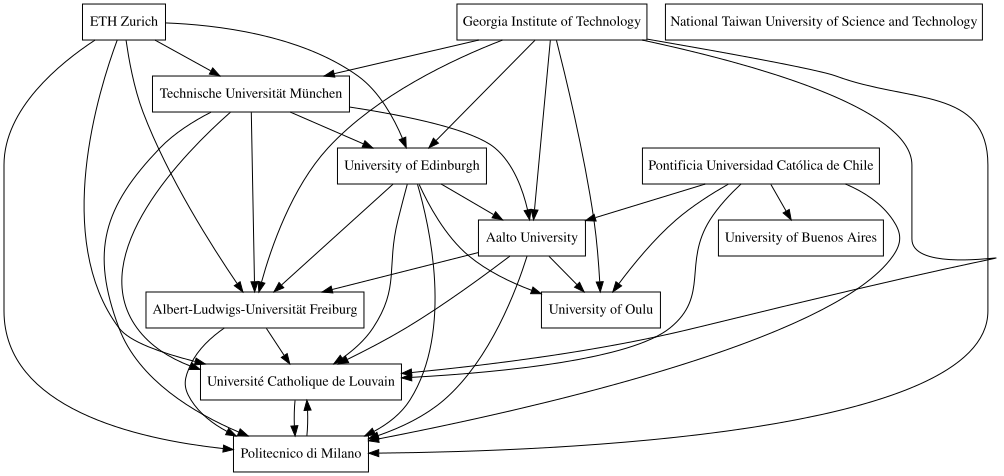

In [ ]:
cut_threshold = 0.6
cred_mat_cut = credibility_matrix.where(credibility_matrix >= cut_threshold, other=0)
AdjacencyMatrix(cred_mat_cut).plot()

[['University of Buenos Aires', 'Georgia Institute of Technology', 'Technische Universität München', 'Pontificia Universidad Católica de Chile', 'ETH Zurich', 'Aalto University', 'National Taiwan University of Science and Technology', 'University of Edinburgh', 'University of Oulu'], ['Albert-Ludwigs-Universität Freiburg'], ['Université Catholique de Louvain'], ['Politecnico di Milano']]


/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, com

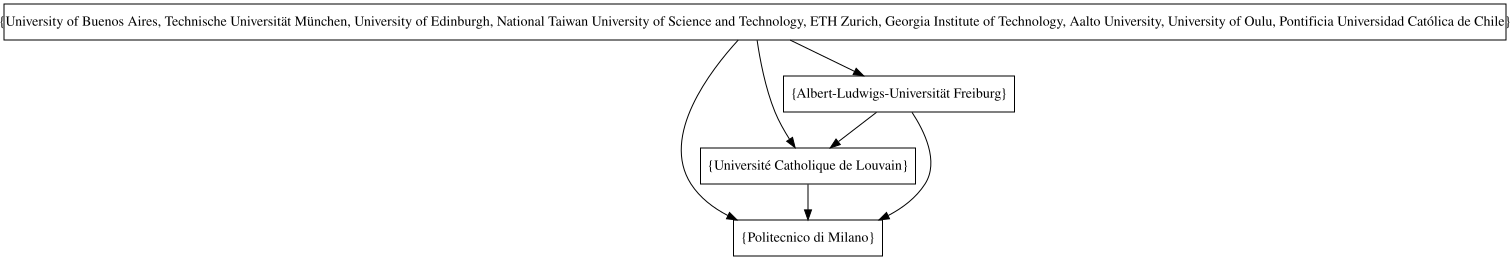

In [ ]:
ascending = electre3.distillation(credibility_matrix, ascending=True)
print(ascending)
ascending_dist_matrix = OutrankingMatrix.from_ranked_categories(ascending)
ascending_dist_matrix.graph_condensation.plot()

[['Technische Universität München'], ['Aalto University', 'University of Edinburgh'], ['Pontificia Universidad Católica de Chile'], ['Albert-Ludwigs-Universität Freiburg', 'University of Buenos Aires', 'Université Catholique de Louvain', 'Politecnico di Milano', 'Georgia Institute of Technology', 'ETH Zurich', 'National Taiwan University of Science and Technology', 'University of Oulu']]


/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, com

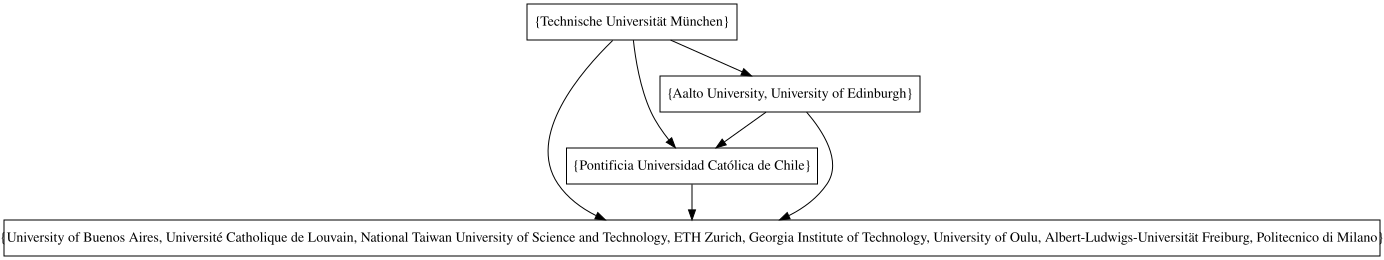

In [ ]:
descending = electre3.distillation(credibility_matrix, ascending=False)
print(descending)
descending_dist_matrix = OutrankingMatrix.from_ranked_categories(descending)
descending_dist_matrix.graph_condensation.plot()

/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, com

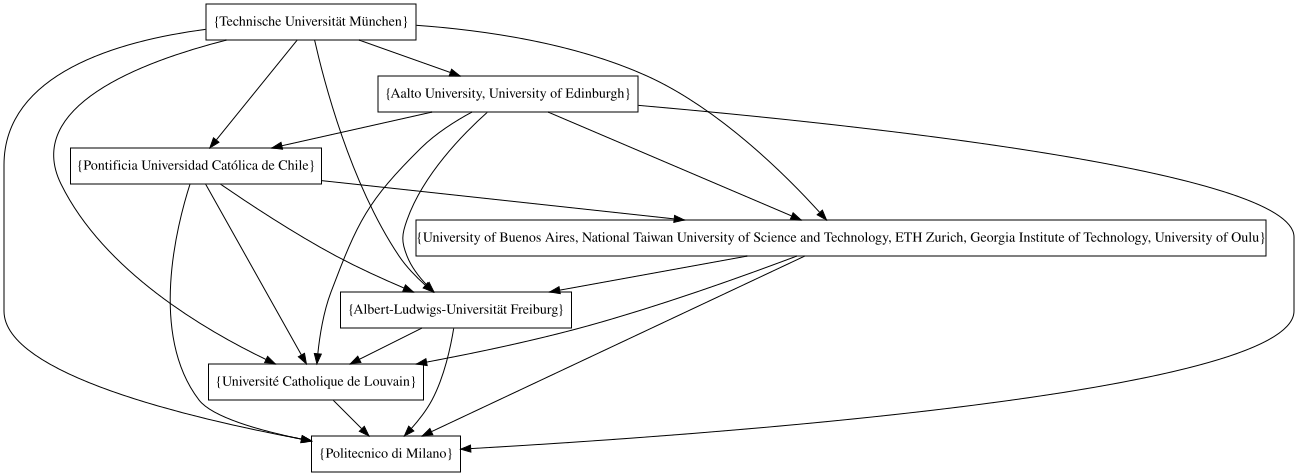

In [ ]:
ranking = electre3.exploit(credibility_matrix)
ranking.graph_condensation.plot()

# Experiment 2: Priority on more future benefit place

In [ ]:
criteria2 = {
    "World Ranking": 0.1,
    "Scholarships (€)": 0.1,
    "Cost of Living (€)": 0.2,
    "Life Expectancy (Years)": 0.25,
    "Salary After Graduation (€)": 0.3,
    "Distance from Barcelona (km)": 0.05
}

# Indifference thresholds for Experiment 2 (q2)
q2 = {
    "World Ranking": 10,             # Slightly less sensitive to ranking differences
    "Scholarships (€)": 700,         # Moderate sensitivity to scholarships
    "Cost of Living (€)": 50,        # More sensitive to cost of living differences
    "Life Expectancy (Years)": 0.5,  # More sensitive to life expectancy differences
    "Salary After Graduation (€)": 1000,  # More sensitive to salary differences
    "Distance from Barcelona (km)": 75   # Slightly more sensitive to distance
}

# Preference thresholds for Experiment 2 (p2)
p2 = {
    "World Ranking": 25,             # Slightly narrower preference threshold for ranking
    "Scholarships (€)": 1200,        # Slightly narrower preference on scholarships
    "Cost of Living (€)": 300,       # Narrower preference on cost of living
    "Life Expectancy (Years)": 3,    # Narrower preference on life expectancy
    "Salary After Graduation (€)": 7000, # Narrower preference on salary
    "Distance from Barcelona (km)": 250  # Slightly narrower preference on distance
}

# Veto thresholds for Experiment 2 (v2)
v2 = {
    "World Ranking": 90,             # Slightly tighter veto on ranking
    "Scholarships (€)": 6000,        # Slightly tighter veto on scholarships
    "Cost of Living (€)": 700,       # Tighter veto on cost of living
    "Life Expectancy (Years)": 8,    # Tighter veto on life expectancy
    "Salary After Graduation (€)": 20000, # Tighter veto on salary
    "Distance from Barcelona (km)": 600  # Slightly tighter veto on distance
}


performance_table = PerformanceTable(
        [[192, 10000, 1200, 81, 55000, 1100],
        [71, 0, 600, 76, 18000, 10000],
        [170, 5000, 1000, 80, 42000, 1200],
        [123, 6000, 1200, 82, 32000, 1200],
        [88, 15000, 1500, 79, 85000, 8000],
        [37, 12000, 1300, 80, 60000, 1400],
        [121, 8000, 800, 81, 28000, 10000],
        [7, 10000, 1800, 84, 90000, 1000],
        [109, 5000, 1100, 82, 48000, 2000],
        [387, 4000, 700, 80, 30000, 11000],
        [22, 7000, 1300, 82, 50000, 1500],
        [313, 6000, 900, 81, 45000, 2100]],
        alternatives = alternatives,
        criteria = criteria2,
        scales = scales)

performance_table.df

,World Ranking,Scholarships (€),Cost of Living (€),Life Expectancy (Years),Salary After Graduation (€),Distance from Barcelona (km)
Albert-Ludwigs-Universität Freiburg,192,10000,1200,81,55000,1100
University of Buenos Aires,71,0,600,76,18000,10000
Université Catholique de Louvain,170,5000,1000,80,42000,1200
Politecnico di Milano,123,6000,1200,82,32000,1200
Georgia Institute of Technology,88,15000,1500,79,85000,8000
Technische Universität München,37,12000,1300,80,60000,1400
Pontificia Universidad Católica de Chile,121,8000,800,81,28000,10000
ETH Zurich,7,10000,1800,84,90000,1000
Aalto University,109,5000,1100,82,48000,2000
National Taiwan University of Science and Technology,387,4000,700,80,30000,11000


,Albert-Ludwigs-Universität Freiburg,University of Buenos Aires,Université Catholique de Louvain,Politecnico di Milano,Georgia Institute of Technology,Technische Universität München,Pontificia Universidad Católica de Chile,ETH Zurich,Aalto University,National Taiwan University of Science and Technology,University of Edinburgh,University of Oulu
Albert-Ludwigs-Universität Freiburg,1.000000,0.500000,0.695714,0.715714,0.250000,0.333333,0.50,0.400000,0.600000,0.750000,0.630000,0.750000
University of Buenos Aires,0.500000,1.000000,0.500000,0.500000,0.500000,0.250000,0.50,0.250000,0.500000,0.400000,0.250000,0.500000
Université Catholique de Louvain,0.580000,0.500000,1.000000,0.600000,0.250000,0.278571,0.39,0.250000,0.381667,0.750000,0.190000,0.676667
Politecnico di Milano,0.600000,0.500000,0.660000,1.000000,0.250000,0.278571,0.60,0.290000,0.553333,0.750000,0.310000,0.500000
Georgia Institute of Technology,0.790000,0.633333,0.830000,0.750000,1.000000,0.640000,0.69,0.483333,0.750000,0.730000,0.560000,0.790000
Technische Universität München,0.950000,0.750000,0.850000,0.910000,0.500000,1.000000,0.73,0.400000,0.750000,0.750000,0.842381,0.730000
Pontificia Universidad Católica de Chile,0.600000,0.660000,0.750000,0.855000,0.350000,0.350000,1.00,0.250000,0.696667,0.828333,0.480000,0.750000
ETH Zurich,0.835714,0.750000,0.778571,0.778571,0.600000,0.600000,0.75,1.000000,0.750000,0.750000,0.750000,0.750000
Aalto University,0.600000,0.500000,0.970000,0.910000,0.316667,0.350000,0.60,0.290000,1.000000,0.750000,0.558333,0.805714
National Taiwan University of Science and Technology,0.330000,0.720000,0.410000,0.498333,0.350000,0.350000,0.58,0.250000,0.350000,1.000000,0.290000,0.330000


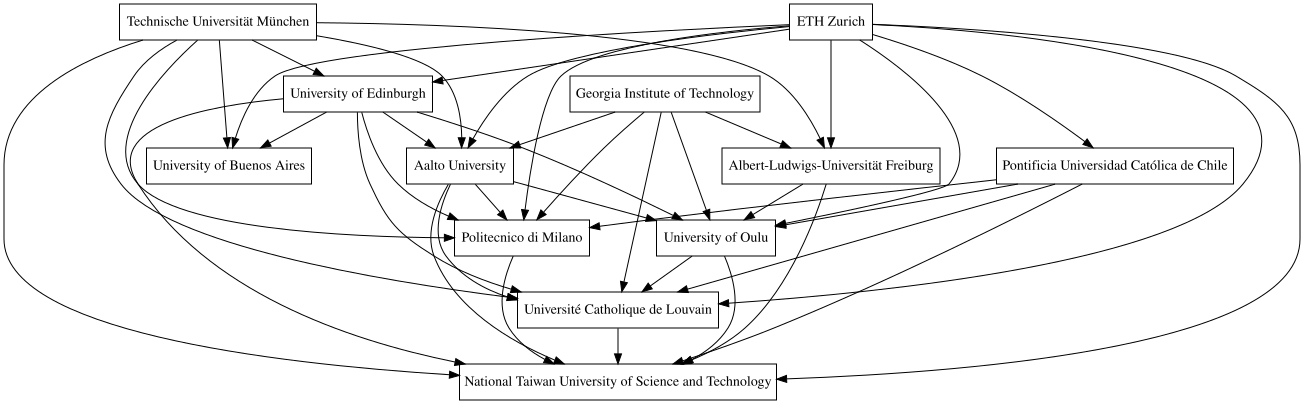

In [ ]:
electre3 = Electre3(criteria_weights=criteria, preference_thresholds=p2, indifference_thresholds=q2, veto_thresholds=v2, alpha=0.2, beta=-0.1)
concordance_matrix = electre3.concordance(performance_table)

display(concordance_matrix)

#Now we plot the graph of concordance with relations above the cut threshold
cut_threshold = 0.75
conc_mat_cut = concordance_matrix.where(concordance_matrix >= cut_threshold, other=0)
AdjacencyMatrix(conc_mat_cut).plot()

In [ ]:
credibility_matrix = electre3.construct(performance_table)
credibility_matrix

credibility_matrix.style.format("{:.3f}")

,Albert-Ludwigs-Universität Freiburg,University of Buenos Aires,Université Catholique de Louvain,Politecnico di Milano,Georgia Institute of Technology,Technische Universität München,Pontificia Universidad Católica de Chile,ETH Zurich,Aalto University,National Taiwan University of Science and Technology,University of Edinburgh,University of Oulu
Albert-Ludwigs-Universität Freiburg,1.000,0.000,0.696,0.716,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
University of Buenos Aires,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Université Catholique de Louvain,0.288,0.000,1.000,0.600,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Politecnico di Milano,0.000,0.000,0.660,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Georgia Institute of Technology,0.790,0.000,0.830,0.750,1.000,0.640,0.000,0.130,0.750,0.000,0.470,0.790
Technische Universität München,0.950,0.000,0.850,0.910,0.000,1.000,0.000,0.000,0.000,0.000,0.842,0.000
Pontificia Universidad Católica de Chile,0.000,0.660,0.750,0.855,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.692
ETH Zurich,0.836,0.000,0.000,0.779,0.000,0.600,0.000,1.000,0.000,0.000,0.750,0.000
Aalto University,0.313,0.000,0.970,0.910,0.000,0.000,0.000,0.000,1.000,0.000,0.058,0.806
National Taiwan University of Science and Technology,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.070


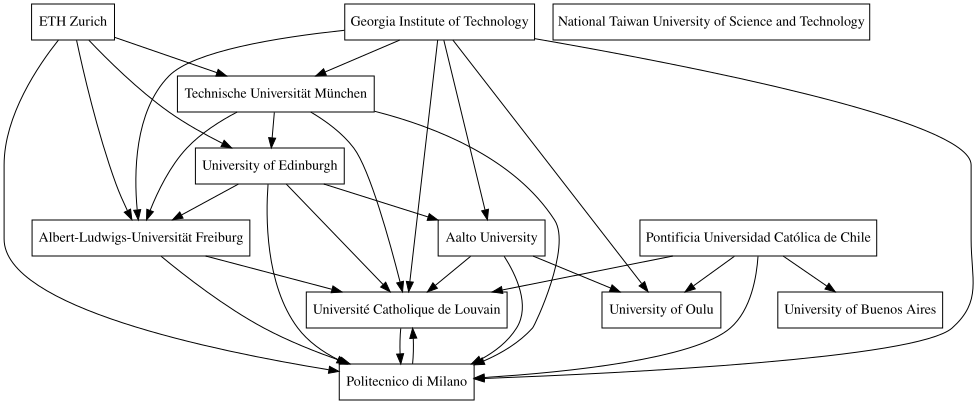

In [ ]:
cut_threshold = 0.6
cred_mat_cut = credibility_matrix.where(credibility_matrix >= cut_threshold, other=0)
AdjacencyMatrix(cred_mat_cut).plot()

[['University of Buenos Aires', 'Georgia Institute of Technology', 'Technische Universität München', 'Pontificia Universidad Católica de Chile', 'ETH Zurich', 'Aalto University', 'National Taiwan University of Science and Technology', 'University of Edinburgh', 'University of Oulu'], ['Albert-Ludwigs-Universität Freiburg', 'Université Catholique de Louvain'], ['Politecnico di Milano']]


/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'True' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, comp

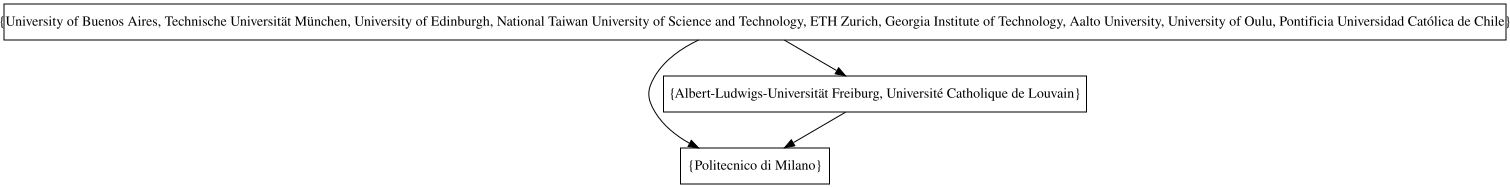

In [ ]:
ascending = electre3.distillation(credibility_matrix, ascending=True)
print(ascending)
ascending_dist_matrix = OutrankingMatrix.from_ranked_categories(ascending)
ascending_dist_matrix.graph_condensation.plot()

[['Technische Universität München', 'Aalto University'], ['University of Edinburgh'], ['Albert-Ludwigs-Universität Freiburg', 'University of Buenos Aires', 'Université Catholique de Louvain', 'Politecnico di Milano', 'Georgia Institute of Technology', 'Pontificia Universidad Católica de Chile', 'ETH Zurich', 'National Taiwan University of Science and Technology', 'University of Oulu']]


/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'True' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, comp

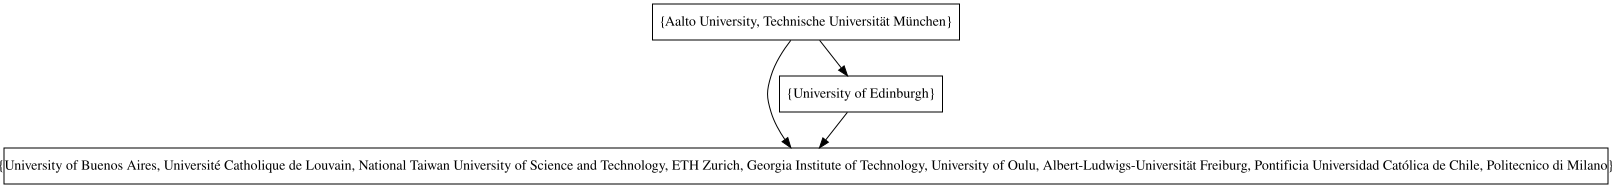

In [ ]:
descending = electre3.distillation(credibility_matrix, ascending=False)
print(descending)
descending_dist_matrix = OutrankingMatrix.from_ranked_categories(descending)
descending_dist_matrix.graph_condensation.plot()

/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, component_b] = (
/usr/local/lib/python3.11/dist-packages/mcda/core/matrices.py:208: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_matrix.iloc[component_a, com

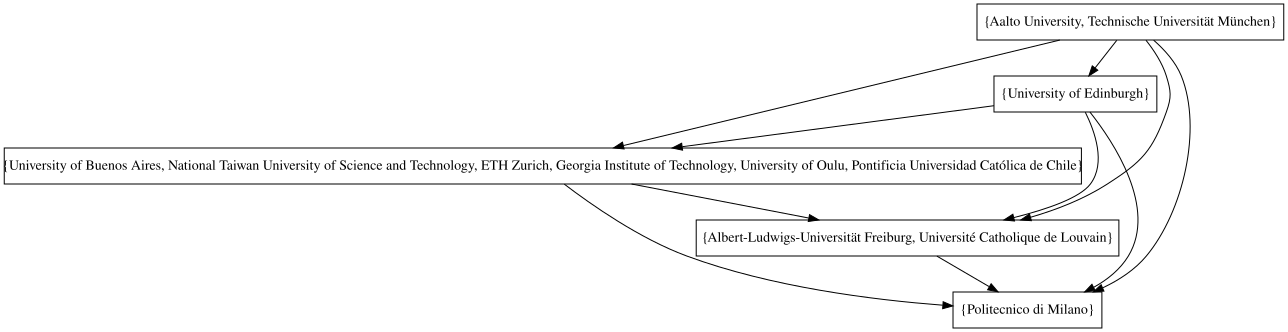

In [ ]:
ranking = electre3.exploit(credibility_matrix)
ranking.graph_condensation.plot()